# Conferencias finais da Fase 3.9

Notebook independente para as duas verificacoes pendentes. Abra **este arquivo local do repositorio**, selecione o runtime Colab e execute as celulas 1, 2 e 3. Nao precisa de token, GPU ou treino. As duas primeiras celulas leem apenas arquivos ja existentes no Drive. A terceira gera galerias de candidatos visuais internos; nao mostra imagens do teste reservado.

Se a lista completa `achados` ainda estiver no mesmo kernel da V3, a terceira celula usa todos os candidatos internos. Se nao estiver, usa os 30 candidatos mais proximos registrados no log da V3 e informa que a revisao e parcial. A classificacao de um par como duplicata exige inspecao visual; dHash e MAE apenas apontam candidatos.


## Passo 1 ? acesso aos arquivos existentes


In [2]:
# 1. Montar Drive e localizar artefatos existentes (sem GitHub e sem GPU).
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/TCC_Final')
RUN = ROOT / 'modelos/fase3_9_tgif_sd2fr_v1'
AUDIT = ROOT / 'resultados/validacao_perguntas_3_9_v1'
MANIFEST = ROOT / 'dados_fase3_9/tgif_sd2fr_768_v1/manifest.json'
SPLITS = RUN / 'split_manifest.json'
for label, path in [('manifesto TGIF', MANIFEST), ('divisoes 3.9', SPLITS), ('pasta de auditoria', AUDIT)]:
    print(label, 'OK' if path.exists() else 'AUSENTE', path)
    if not path.exists(): raise FileNotFoundError(path)
print('Preparacao pronta; nenhuma imagem foi avaliada pelo modelo.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
manifesto TGIF OK /content/drive/MyDrive/TCC_Final/dados_fase3_9/tgif_sd2fr_768_v1/manifest.json
divisoes 3.9 OK /content/drive/MyDrive/TCC_Final/modelos/fase3_9_tgif_sd2fr_v1/split_manifest.json
pasta de auditoria OK /content/drive/MyDrive/TCC_Final/resultados/validacao_perguntas_3_9_v1
Preparacao pronta; nenhuma imagem foi avaliada pelo modelo.


## Passo 2 ? pares TGIF


In [3]:
# 2. Conferir pares TGIF diretamente no manifesto e salvar comprovante datado.
import hashlib, json
from collections import Counter, defaultdict
from datetime import datetime, timezone
rows = json.loads(MANIFEST.read_text(encoding='utf-8')).get('rows', [])
pairs = defaultdict(list)
for row in rows:
    pairs[(row['subset'], row['image_id'])].append(row)
counts = Counter((row['subset'], int(row['label'])) for row in rows)
expected = {('train', 0): 512, ('train', 1): 512,
            ('validation_selection', 0): 128, ('validation_selection', 1): 128,
            ('validation_calibration', 0): 128, ('validation_calibration', 1): 128}
valid = (len(rows) == 1536 and len(pairs) == 768 and counts == expected and
         all(len(group) == 2 and {int(row['label']) for row in group} == {0, 1}
             for group in pairs.values()))
print('Registros:', len(rows), '| pares completos:', len(pairs), '| contagens:', dict(counts))
if not valid:
    raise ValueError('O manifesto TGIF nao confirmou os 768 pares e as divisoes previstas')
latest_v2 = sorted(AUDIT.glob('v2_tgif_e_formato_*_UTC.json'))
latest_closure = sorted(AUDIT.glob('fechamento_fase3_9_*_UTC.json'))
latest_log = sorted((AUDIT / 'logs').glob('fase3_9_final_*_UTC.log'))
if not latest_log: raise FileNotFoundError('Log da celula 13 nao encontrado no Drive')
v2 = json.loads(latest_v2[-1].read_text(encoding='utf-8')) if latest_v2 else {}
closure = json.loads(latest_closure[-1].read_text(encoding='utf-8')) if latest_closure else {}
print('V2 mais recente: pares identificados =', v2.get('tgif_pares_identificados', 'nao informado'))
print('Fechamento mais recente: status =', closure.get('status', 'nao informado'))
print('Avisos do fechamento:', closure.get('warnings', []))
print('Log encontrado:', latest_log[-1])
report = {'check': 'tgif_pairs', 'result': 'confirmed', 'rows': len(rows), 'pairs': len(pairs),
          'counts': {f'{split}|{label}': n for (split, label), n in counts.items()},
          'manifest_sha256': hashlib.sha256(MANIFEST.read_bytes()).hexdigest(),
          'latest_v2': str(latest_v2[-1]) if latest_v2 else None,
          'latest_v2_pairs': v2.get('tgif_pares_identificados'),
          'latest_closure': str(latest_closure[-1]) if latest_closure else None,
          'latest_closure_warnings': closure.get('warnings', []),
          'latest_log': str(latest_log[-1])}
PAIR_REPORT = AUDIT / ('conferencia_pares_tgif_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f_UTC') + '.json')
with PAIR_REPORT.open('x', encoding='utf-8') as handle: json.dump(report, handle, indent=2, ensure_ascii=False)
print('CONFERENCIA 1 OK: 768 pares reais/sinteticos, 512/128/128 por divisao.')
print('Comprovante:', PAIR_REPORT)


Registros: 1536 | pares completos: 768 | contagens: {('train', 0): 512, ('train', 1): 512, ('validation_selection', 0): 128, ('validation_selection', 1): 128, ('validation_calibration', 0): 128, ('validation_calibration', 1): 128}
V2 mais recente: pares identificados = 768
Fechamento mais recente: status = revisao_tecnica_pendente
Avisos do fechamento: ['Candidatos visuais dHash exigem revisão; similaridade não prova duplicata.']
Log encontrado: /content/drive/MyDrive/TCC_Final/resultados/validacao_perguntas_3_9_v1/logs/fase3_9_final_20261110_212024_787435_UTC.log
CONFERENCIA 1 OK: 768 pares reais/sinteticos, 512/128/128 por divisao.
Comprovante: /content/drive/MyDrive/TCC_Final/resultados/validacao_perguntas_3_9_v1/conferencia_pares_tgif_20261110_213426_837279_UTC.json


## Passo 3 ? candidatos visuais internos


Candidatos internos localizados: 19 | cobertura: apenas candidatos impressos no log da V3 (ate 30 de 71 totais)
Imagens copiadas e comparadas: 10/19 | 0.0 min
Imagens copiadas e comparadas: 19/19 | 0.0 min
Galeria: /content/drive/MyDrive/TCC_Final/resultados/validacao_perguntas_3_9_v1/revisao_visual_interna_20261110_213427_368834_UTC/galeria_01.jpg


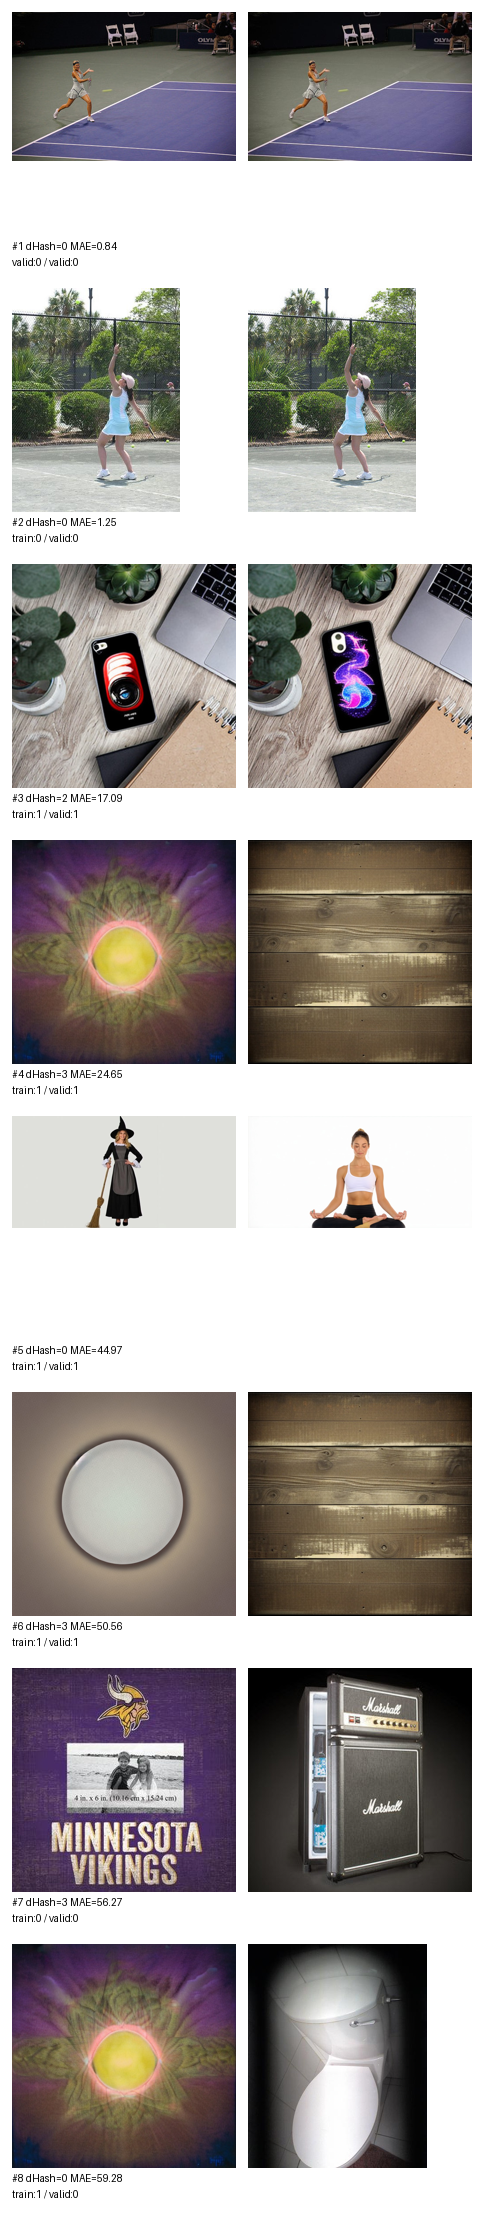

Galeria: /content/drive/MyDrive/TCC_Final/resultados/validacao_perguntas_3_9_v1/revisao_visual_interna_20261110_213427_368834_UTC/galeria_02.jpg
Galeria: /content/drive/MyDrive/TCC_Final/resultados/validacao_perguntas_3_9_v1/revisao_visual_interna_20261110_213427_368834_UTC/galeria_03.jpg
CONFERENCIA 2: galerias prontas para inspecao humana em /content/drive/MyDrive/TCC_Final/resultados/validacao_perguntas_3_9_v1/revisao_visual_interna_20261110_213427_368834_UTC
Envie as galerias e o resumo.json para revisao; nenhum resultado de modelo foi alterado.


In [4]:
# 3. Gerar galerias de candidatos internos e relatorio de cobertura.
# Usa todos os candidatos da V3 se estiverem na memoria; caso contrario, usa os 30 impressos no log.
import csv, json, re, shutil, time
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
from PIL import Image, ImageDraw, ImageOps
try:
    from IPython.display import display
except ImportError:
    def display(image): print('Galeria salva no Drive; exibicao inline indisponivel.')

splits = json.loads(SPLITS.read_text(encoding='utf-8'))
v3_files = sorted(AUDIT.glob('v3_duplicatas_e_baseline_*_UTC.json'))
if not v3_files: raise FileNotFoundError('Relatorio V3 nao encontrado no Drive')
v3_counts = json.loads(v3_files[-1].read_text(encoding='utf-8')).get('candidatos_dhash', {})
v3_total = sum(int(value) for value in v3_counts.values())
lookup = defaultdict(list)
for split in ('train', 'validation_selection', 'validation_calibration'):
    for row in splits[split]:
        lookup[(int(row['label']), row['group'], Path(row['path']).name)].append((split, row['path']))

def parse_side(text):
    prefix, label, rest = text.strip().split(':', 2)
    group, filename = rest.rsplit(':', 1)
    matches = [(split, path) for split, path in lookup[(int(label), group, filename)]
               if split.startswith(prefix)]
    if len(matches) != 1:
        raise ValueError(f'Candidato ambiguo/ausente: {prefix}:{label}:{group}:{filename} ({len(matches)} caminhos)')
    return {'split': matches[0][0], 'label': int(label), 'group': group, 'path': matches[0][1]}

candidates = []
if 'achados' in globals() and achados:
    for distance, split_a, split_b, a, b in achados:
        if 'test_reserved' in (split_a, split_b): continue
        candidates.append((int(distance), {'split':split_a,'label':int(a['label']),'group':a['group'],'path':a['path']},
                           {'split':split_b,'label':int(b['label']),'group':b['group'],'path':b['path']}))
    coverage = 'todos os candidatos internos da V3 em memoria'
else:
    log = latest_log[-1].read_text(encoding='utf-8')
    for line in log.splitlines():
        if not line.strip().startswith('dHash='): continue
        parts = line.split('|')
        if len(parts) != 3: continue
        match = re.search(r'dHash=(\d+)\s+MAE=\s*([0-9.]+)', parts[0])
        if not match or any('test_' in part for part in parts[1:]): continue
        candidates.append((int(match.group(1)), parse_side(parts[1]), parse_side(parts[2])))
    coverage = f'apenas candidatos impressos no log da V3 (ate 30 de {v3_total} totais)'
if not candidates: raise ValueError('Nenhum candidato interno localizado; confira o log da V3')
print('Candidatos internos localizados:', len(candidates), '| cobertura:', coverage)

# Copiar somente as imagens selecionadas para /content antes da leitura, sem mudar dados no Drive.
cache = Path('/content/fase3_9_revisao_visual')
cache.mkdir(parents=True, exist_ok=True)
def local(path):
    source = Path(path)
    target = cache / (hashlib.sha256(str(source).encode()).hexdigest()[:24] + source.suffix.lower())
    if not target.is_file() or target.stat().st_size != source.stat().st_size:
        shutil.copyfile(source, target)
    return target

def rgb96(path):
    with Image.open(path) as image:
        return np.asarray(image.convert('RGB').resize((96, 96), Image.Resampling.BICUBIC), dtype=np.float32)

records = []
start = time.monotonic()
for number, (distance, a, b) in enumerate(candidates, 1):
    pa, pb = local(a['path']), local(b['path'])
    mae = float(np.abs(rgb96(pa)-rgb96(pb)).mean())
    records.append({'dhash':distance,'mae_rgb_96':round(mae,3),
                    'split_a':a['split'],'label_a':a['label'],'group_a':a['group'],'path_a':a['path'],
                    'split_b':b['split'],'label_b':b['label'],'group_b':b['group'],'path_b':b['path'],
                    'visual_decision':'','review_note':''})
    if number % 10 == 0 or number == len(candidates):
        print(f'Imagens copiadas e comparadas: {number}/{len(candidates)} | {(time.monotonic()-start)/60:.1f} min', flush=True)
records.sort(key=lambda row:(row['mae_rgb_96'],row['dhash']))
folder = AUDIT / ('revisao_visual_interna_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f_UTC'))
folder.mkdir(parents=True,exist_ok=False)
with (folder/'candidatos.csv').open('x',newline='',encoding='utf-8') as handle:
    writer=csv.DictWriter(handle,fieldnames=list(records[0]));writer.writeheader();writer.writerows(records)
summary={'source':coverage,'pairs_in_gallery':len(records),'v3_candidates_total_reported':v3_total,
         'test_reserved_displayed':False,'visual_review_complete':False,
         'note':'Galeria exige inspecao humana; dHash e MAE nao provam identidade.'}
with (folder/'resumo.json').open('x',encoding='utf-8') as handle:json.dump(summary,handle,indent=2,ensure_ascii=False)
for offset in range(0,len(records),8):
    page=records[offset:offset+8]
    sheet=Image.new('RGB',(484,len(page)*276+12),'white');draw=ImageDraw.Draw(sheet)
    for j,row in enumerate(page):
        y=12+j*276
        for k,key in enumerate(('path_a','path_b')):
            with Image.open(local(row[key])) as image:
                thumb=ImageOps.contain(image.convert('RGB'),(224,224))
            sheet.paste(thumb,(12+k*236,y))
        draw.text((12,y+228),f'#{offset+j+1} dHash={row["dhash"]} MAE={row["mae_rgb_96"]:.2f}',fill='black')
        draw.text((12,y+244),f'{row["split_a"][:5]}:{row["label_a"]} / {row["split_b"][:5]}:{row["label_b"]}',fill='black')
    target=folder/f'galeria_{offset//8+1:02d}.jpg';sheet.save(target,quality=85)
    print('Galeria:',target,flush=True)
    if offset==0:display(sheet)
print('CONFERENCIA 2: galerias prontas para inspecao humana em',folder)
print('Envie as galerias e o resumo.json para revisao; nenhum resultado de modelo foi alterado.')
